# ステップ1-2 演習: 2変数データ

この Notebook は、本文 [ステップ1-2 記述統計: 2変数データ](../docs/step1-2_bivariate.md) の演習です。本文の手計算の例を Python で検算し、続いて工学の例題として、温度・湿度・センサ出力の関係を調べます。

上のセルから順に実行してください。4-2節は、2-3節で定義する関数を使うので、2-3節を先に実行しておく必要があります。模擬データを作る節（3節・4節）では、それぞれの節の始めで乱数の生成器を同じシードから作り直します。そのため、節を飛ばしたり再実行したりしても、同じ版の NumPy なら同じ模擬データになります（NumPy の版によっては、値がわずかに変わることがあります）。

## 1. 準備

使うパッケージを読み込み、乱数のシードを決めます。

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# 乱数のシード。模擬データを作る節の始めで、この値から生成器を作り直す
SEED = 20261017

## 2. 本文の手計算を検算する

### 2-1. 共分散と相関係数

本文の3節・4節で手計算した、温度（℃）とセンサ出力（mV）の5組のデータです。`np.cov` の既定は $n-1$ で割る共分散、`np.corrcoef` は相関係数を、どちらも行列の形で返します。

In [2]:
temp = np.array([10, 20, 30, 40, 50])
out = np.array([101, 104, 104, 108, 108])

cov = np.cov(temp, out)[0, 1]
r = np.corrcoef(temp, out)[0, 1]
print(f"温度の平均 {temp.mean():.1f}  出力の平均 {out.mean():.1f}")
print(f"共分散     {cov:.2f}")
print(f"標準偏差   温度 {temp.std(ddof=1):.3f}  出力 {out.std(ddof=1):.3f}")
print(f"相関係数   {r:.4f}")

温度の平均 30.0  出力の平均 105.0
共分散     45.00
標準偏差   温度 15.811  出力 3.000
相関係数   0.9487


### 2-2. 単位を換算しても相関係数は変わらない

本文の4-3節の性質を確かめます。温度を華氏（°F = 1.8 × ℃ + 32）に、出力を V（mV ÷ 1000）に換算しても、相関係数は変わりません。一方、片方の符号を反転すると、相関係数の符号も反転します。

In [3]:
temp_f = 1.8 * temp + 32
out_v = out / 1000
print(f"換算後の相関係数       {np.corrcoef(temp_f, out_v)[0, 1]:.4f}")
print(f"共分散（換算後）       {np.cov(temp_f, out_v)[0, 1]:.5f}")
print(f"片方の符号を反転した相関係数 {np.corrcoef(-temp, out)[0, 1]:.4f}")

換算後の相関係数       0.9487
共分散（換算後）       0.08100
片方の符号を反転した相関係数 -0.9487


### 2-3. 偏相関係数

本文の6-2節の例（ $r_{xy} = 0.6$ 、 $r_{xz} = 0.8$ 、 $r_{yz} = 0.75$ ）で、 $z$ の影響を除いた $x$ と $y$ の偏相関係数を求めます。

In [4]:
def partial_corr(r_xy, r_xz, r_yz):
    """z の影響を除いた x と y の偏相関係数を、3つの相関係数から求める"""
    return (r_xy - r_xz * r_yz) / np.sqrt((1 - r_xz**2) * (1 - r_yz**2))


# 計算の丸めで -0.0000 と表示されないよう、小さな誤差を丸めてから表示する
print(f"偏相関係数 {round(partial_corr(0.6, 0.8, 0.75), 10) + 0.0:.4f}")

偏相関係数 0.0000


### 2-4. クロス表の割合

本文の8-1節のクロス表（2つの製造ラインの、外観検査の判定の件数）から、行ごとの割合（各ラインの中での良・不良の割合）と、不良の列の割合（不良品のうち各ラインで作られたものの割合）を求めます。続いて、本文の8-2節のモザイク図を描きます。

line 1  件数 [180  20]  合計 200  良 90.0%  不良 10.0%
line 2  件数 [255  45]  合計 300  良 85.0%  不良 15.0%
全体    件数 [435  65]  合計 500  良 87.0%  不良 13.0%
不良品のうち各ラインの割合  line 1 30.8%  line 2 69.2%


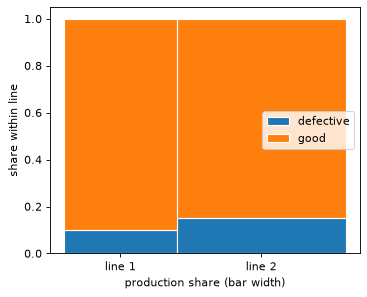

In [5]:
lines = ["line 1", "line 2"]
table = np.array([[180, 20],
                  [255, 45]])
row_share = table / table.sum(axis=1, keepdims=True)
for name, counts, share in zip(lines, table, row_share):
    print(f"{name}  件数 {counts}  合計 {counts.sum()}  良 {share[0]:.1%}  不良 {share[1]:.1%}")
total = table.sum(axis=0)
print(f"全体    件数 {total}  合計 {total.sum()}  良 {total[0] / total.sum():.1%}  不良 {total[1] / total.sum():.1%}")
col_share = table[:, 1] / table[:, 1].sum()
print(f"不良品のうち各ラインの割合  line 1 {col_share[0]:.1%}  line 2 {col_share[1]:.1%}")

# モザイク図: 帯の横幅を各ラインの生産量の割合に、帯の中の高さを行の割合にする
widths = table.sum(axis=1) / table.sum()
lefts = np.concatenate([[0.0], np.cumsum(widths)[:-1]])
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(lefts, row_share[:, 1], width=widths, align="edge", edgecolor="white", label="defective")
ax.bar(lefts, row_share[:, 0], width=widths, bottom=row_share[:, 1], align="edge",
       edgecolor="white", label="good")
ax.set_xticks(lefts + widths / 2, lines)
ax.set_xlabel("production share (bar width)")
ax.set_ylabel("share within line")
ax.legend(loc="center right")
plt.show()

## 3. 相関係数だけでは分からないこと

本文の5節の内容を、模擬データで確かめます。次の4つのデータ（各30組）の散布図と相関係数を並べます。

- (a) 直線的な関係に、ばらつきが乗ったもの
- (b) 関係が無いデータに、1点だけ大きく外れた点が加わったもの
- (c) U字形（曲線）の関係（横軸の値を左右対称に並べた）
- (d) 関係が無いもの

(a) linear           r = 0.876
(b) one far point    r = 0.743
(c) U-shaped         r = -0.069
(d) no relation      r = -0.202
(b) から外れた1点を除いた r = -0.165


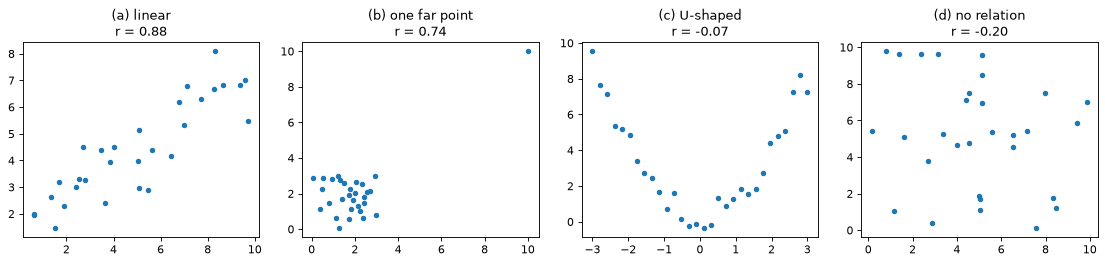

In [6]:
rng = np.random.default_rng(seed=SEED)
n = 30

x_a = rng.uniform(0, 10, size=n)
y_a = 2.0 + 0.5 * x_a + rng.normal(0, 1.0, size=n)

x_b = np.append(rng.uniform(0, 3, size=n - 1), 10.0)
y_b = np.append(rng.uniform(0, 3, size=n - 1), 10.0)

x_c = np.linspace(-3, 3, n)
y_c = x_c**2 + rng.normal(0, 0.5, size=n)

x_d = rng.uniform(0, 10, size=n)
y_d = rng.uniform(0, 10, size=n)

cases = [("(a) linear", x_a, y_a), ("(b) one far point", x_b, y_b),
         ("(c) U-shaped", x_c, y_c), ("(d) no relation", x_d, y_d)]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, (name, xs, ys) in zip(axes, cases):
    r = np.corrcoef(xs, ys)[0, 1]
    ax.scatter(xs, ys, s=15)
    ax.set_title(f"{name}\nr = {r:.2f}")
    print(f"{name:20s} r = {r:.3f}")
plt.tight_layout()
plt.show()

r_b_without = np.corrcoef(x_b[:-1], y_b[:-1])[0, 1]
print(f"(b) から外れた1点を除いた r = {r_b_without:.3f}")

## 4. 工学の例題: 温度・湿度・センサ出力

ある工場で、圧力センサの出力（mV、一定の圧力をかけたときの値）を、60日間、毎日1回記録しました。同時に、その時刻の室温（℃）と湿度（%）も記録しています。模擬データの条件は次のとおりです。

- 室温: 15〜35 ℃の範囲で日によって変わる
- 湿度: 室温が高い日ほど低くなる傾向があり、それに日ごとのばらつきが乗る
- センサ出力: 室温が 1 ℃上がるごとに 0.5 mV 大きくなる（温度の影響）。湿度の影響は **無い**。それに測定のばらつきが乗る

データを読む側は、この条件を知らないものとして、「センサ出力に影響しているのは何か」を調べます。

In [7]:
rng = np.random.default_rng(seed=SEED)
n_days = 60
room_temp = rng.uniform(15, 35, size=n_days)
humidity = 60 - 1.5 * (room_temp - 25) + rng.normal(0, 4, size=n_days)
sensor_out = 100 + 0.5 * room_temp + rng.normal(0, 1.0, size=n_days)

### 4-1. 散布図と相関行列

3つの変数の組み合わせごとの散布図と、相関係数を並べた相関行列を求めます。

相関行列（行・列の順: 室温, 湿度, センサ出力）
[[ 1.    -0.932  0.931]
 [-0.932  1.    -0.877]
 [ 0.931 -0.877  1.   ]]


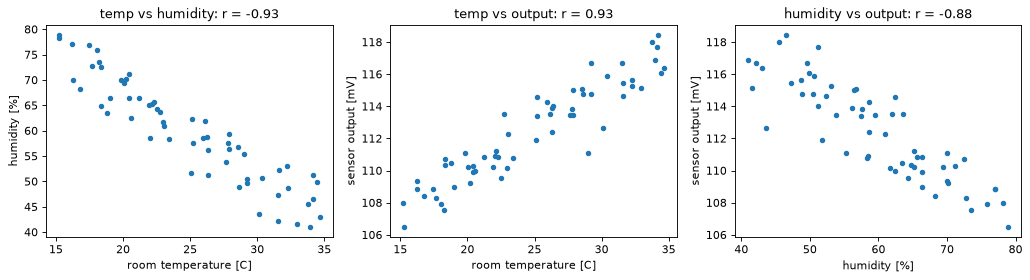

In [8]:
data = np.vstack([room_temp, humidity, sensor_out])
names = ["temp", "humidity", "output"]
corr = np.corrcoef(data)

print("相関行列（行・列の順: 室温, 湿度, センサ出力）")
print(np.round(corr, 3))

pairs = [(0, 1), (0, 2), (1, 2)]
labels = ["room temperature [C]", "humidity [%]", "sensor output [mV]"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (i, j) in zip(axes, pairs):
    ax.scatter(data[i], data[j], s=15)
    ax.set_xlabel(labels[i])
    ax.set_ylabel(labels[j])
    ax.set_title(f"{names[i]} vs {names[j]}: r = {corr[i, j]:.2f}")
plt.tight_layout()
plt.show()

### 4-2. 偏相関係数で室温の影響を除く

湿度とセンサ出力の相関が、室温を通した見かけのものかを確かめます。2-3節で定義した関数 `partial_corr` を使います。室温の影響を除いた、湿度とセンサ出力の偏相関係数を求めます。比べるため、湿度の影響を除いた、室温とセンサ出力の偏相関係数も求めます。

In [9]:
r_th, r_to, r_ho = corr[0, 1], corr[0, 2], corr[1, 2]
print(f"湿度と出力の相関係数                 {r_ho:.3f}")
print(f"室温の影響を除いた、湿度と出力の偏相関係数 {partial_corr(r_ho, r_th, r_to):.3f}")
print(f"室温と出力の相関係数                 {r_to:.3f}")
print(f"湿度の影響を除いた、室温と出力の偏相関係数 {partial_corr(r_to, r_th, r_ho):.3f}")

湿度と出力の相関係数                 -0.877
室温の影響を除いた、湿度と出力の偏相関係数 -0.072
室温と出力の相関係数                 0.931
湿度の影響を除いた、室温と出力の偏相関係数 0.653


### 4-3. 層別: 2つのロットを混ぜると

同じ型のセンサを、ロット1とロット2から1台ずつ選び、室温の違う時期にそれぞれ30回ずつ出力を測ったとします（室温は操作せず、その時期の室温をそのまま記録した）。模擬データの条件は次のとおりです。

- ロット1のセンサ: 室温 25〜35 ℃の時期に測った。出力は室温 1 ℃あたり 0.5 mV 大きくなる
- ロット2のセンサ: 室温 15〜25 ℃の時期に測った。温度の影響はロット1のセンサと同じだが、出力が全体に約 8 mV 大きい（1台ずつなので、ロットの差か個体の差かは区別できない）

2つのロットを区別せずに散布図を描いた場合と、ロットで色分けした（層別した）場合を比べます。

区別しない場合の相関係数 -0.306
ロット1の中の相関係数     0.912
ロット2の中の相関係数     0.842


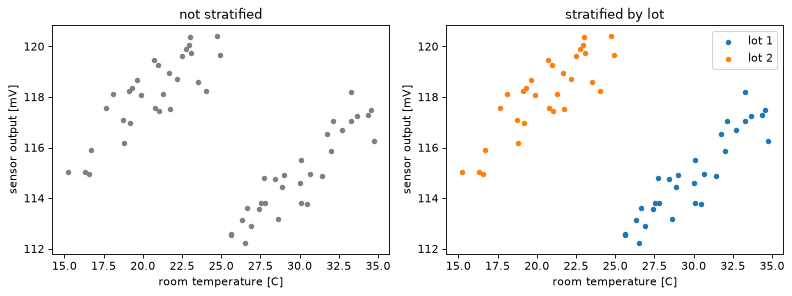

In [10]:
rng = np.random.default_rng(seed=SEED)
t1 = rng.uniform(25, 35, size=30)
o1 = 100 + 0.5 * t1 + rng.normal(0, 0.8, size=30)
t2 = rng.uniform(15, 25, size=30)
o2 = 108 + 0.5 * t2 + rng.normal(0, 0.8, size=30)
t_all = np.concatenate([t1, t2])
o_all = np.concatenate([o1, o2])

print(f"区別しない場合の相関係数 {np.corrcoef(t_all, o_all)[0, 1]:.3f}")
print(f"ロット1の中の相関係数     {np.corrcoef(t1, o1)[0, 1]:.3f}")
print(f"ロット2の中の相関係数     {np.corrcoef(t2, o2)[0, 1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].scatter(t_all, o_all, s=15, color="gray")
axes[0].set_title("not stratified")
axes[1].scatter(t1, o1, s=15, label="lot 1")
axes[1].scatter(t2, o2, s=15, label="lot 2")
axes[1].set_title("stratified by lot")
axes[1].legend()
for ax in axes:
    ax.set_xlabel("room temperature [C]")
    ax.set_ylabel("sensor output [mV]")
plt.tight_layout()
plt.show()

## 5. まとめ

- 湿度とセンサ出力の間には、はっきりした負の相関が見える。しかし室温の影響を除いた偏相関係数はほぼ0で、湿度と出力の相関は、室温が両方に影響していることによる見かけの相関だと考えられる。
- 室温とセンサ出力の相関は、湿度の影響を除いても強いまま残る。出力に影響しているのは室温だと考えるのが自然である。
- 2つのロットを区別せずに見ると、室温と出力の相関は負になる。ロットで層別すると、どちらのロットの中でも正の相関がある。性質の違う集団が混ざったデータでは、層別しないと関係の向きまで見誤ることがある。
- 相関係数は直線的な関係の強さだけを表す1つの数値で、散布図と組み合わせて読む必要がある（3節）。

読み方の詳しい説明は、本文の9節にあります。